In [ ]:
!pip install boto3 soundfile numpy librosa torch torchvision scikit-learn matplotlib pandas tqdm plotly panns-inference birdnetlib tensorflow

In [3]:
import boto3
import soundfile as sf
import numpy as np
import librosa
from io import BytesIO
from panns_inference import AudioTagging
import torch
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm

In [4]:
ACCESS_KEY = "WO63GMJEEJMBWDKIPUKV"
SECRET_KEY = "yHBzr9SfSEDGN0y8PALguMoeQ4lyBrtUJcquMjer"
ENDPOINT = "https://s3.eu-west-2.wasabisys.com"
BUCKET = "ecosurf-dataset"
PREFIX = "2019/S4A09154/Data/"

s3 = boto3.client('s3',
    endpoint_url=ENDPOINT,
    aws_access_key_id=ACCESS_KEY,
    aws_secret_access_key=SECRET_KEY
)

response = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIX, MaxKeys=50)
audio_files = [obj['Key'] for obj in response['Contents'] if obj['Key'].endswith('.flac')]
print(f"Nombre de fichiers: {len(audio_files)}")

Nombre de fichiers: 50


In [5]:
from panns_inference import AudioTagging
model = AudioTagging(checkpoint_path=None, device='cuda' if torch.cuda.is_available() else 'cpu')
print("PANNs chargé")

Checkpoint path: C:\Users\cheml/panns_data/Cnn14_mAP=0.431.pth


c:\Users\cheml\anaconda3\Lib\site-packages\panns_inference\inference.py:55: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_locati

Using CPU.
PANNs chargé


In [6]:
model = AudioTagging(checkpoint_path=None, device='cuda' if torch.cuda.is_available() else 'cpu')
print("PANNs chargé")

Checkpoint path: C:\Users\cheml/panns_data/Cnn14_mAP=0.431.pth
Using CPU.
PANNs chargé


### Fonction pour extraire les embeddings

In [7]:
def get_embeddings_from_audio(s3, bucket, key, model, segment_duration=10):
    obj = s3.get_object(Bucket=bucket, Key=key)
    audio_data = BytesIO(obj['Body'].read())
    data, sr = sf.read(audio_data)
    
    if len(data.shape) > 1:
        data = data[:, 0]
    
    if sr != 32000:
        data = librosa.resample(data.astype(np.float32), orig_sr=sr, target_sr=32000)
        sr = 32000
    
    embeddings = []
    segments_info = []
    
    total_samples = len(data)
    segment_samples = segment_duration * sr
    
    for start in range(0, total_samples - segment_samples, segment_samples):
        segment = data[start:start + segment_samples].astype(np.float32)
        segment = segment[None, :]
        
        _, emb = model.inference(segment)
        embeddings.append(emb[0])
        segments_info.append({'file': key, 'start': start/sr, 'end': (start + segment_samples)/sr})
    
    return embeddings, segments_info

### Extraire les embeddings pour tous les fichiers

In [8]:
all_embeddings = []
all_info = []

for audio_file in tqdm(audio_files[:50]):
    try:
        embs, infos = get_embeddings_from_audio(s3, BUCKET, audio_file, model, segment_duration=10)
        all_embeddings.extend(embs)
        all_info.extend(infos)
    except Exception as e:
        print(f"Erreur {audio_file}: {e}")

embeddings_array = np.array(all_embeddings)
print(f"Embeddings shape: {embeddings_array.shape}")

100%|██████████| 50/50 [06:21<00:00,  7.63s/it]

Embeddings shape: (250, 2048)


### Clustering K-Means

In [9]:
n_clusters = 10
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
labels = kmeans.fit_predict(embeddings_array)
print(f"Clusters: {np.bincount(labels)}")

c:\Users\cheml\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Clusters: [46 30 26 20 20 33 20 28 15 12]


In [10]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
embeddings_2d = tsne.fit_transform(embeddings_array)
print("t-SNE terminé")

t-SNE terminé


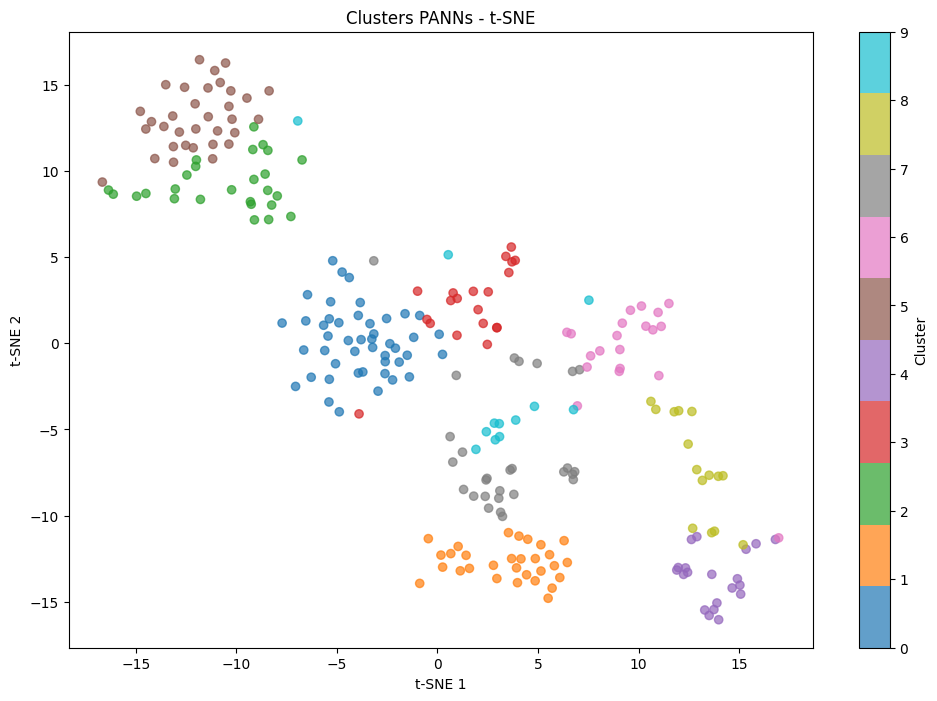

In [11]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', alpha=0.7)
plt.colorbar(scatter, label='Cluster')
plt.title('Clusters PANNs - t-SNE')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

In [12]:
df = pd.DataFrame(all_info)
df['cluster'] = labels
df['tsne_1'] = embeddings_2d[:, 0]
df['tsne_2'] = embeddings_2d[:, 1]

for cluster_id in range(n_clusters):
    cluster_data = df[df['cluster'] == cluster_id]
    print(f"\n=== Cluster {cluster_id} ({len(cluster_data)} segments) ===")
    print(cluster_data[['file', 'start', 'end']].head(5))


=== Cluster 0 (46 segments) ===
                                                 file  start   end
67   2019/S4A09154/Data/S4A09154_20190218_194500.flac   20.0  30.0
89   2019/S4A09154/Data/S4A09154_20190218_204500.flac   40.0  50.0
93   2019/S4A09154/Data/S4A09154_20190218_210000.flac   30.0  40.0
97   2019/S4A09154/Data/S4A09154_20190218_211500.flac   20.0  30.0
106  2019/S4A09154/Data/S4A09154_20190218_214500.flac   10.0  20.0

=== Cluster 1 (30 segments) ===
                                                 file  start   end
139  2019/S4A09154/Data/S4A09154_20190218_231500.flac   40.0  50.0
200  2019/S4A09154/Data/S4A09154_20190219_023000.flac    0.0  10.0
213  2019/S4A09154/Data/S4A09154_20190219_030000.flac   30.0  40.0
214  2019/S4A09154/Data/S4A09154_20190219_030000.flac   40.0  50.0
221  2019/S4A09154/Data/S4A09154_20190219_033000.flac   10.0  20.0

=== Cluster 2 (26 segments) ===
                                                file  start   end
81  2019/S4A09154/Data/S4A09154

In [13]:
def play_segment(s3, bucket, key, start, duration=10):
    obj = s3.get_object(Bucket=bucket, Key=key)
    audio_data = BytesIO(obj['Body'].read())
    data, sr = sf.read(audio_data)
    if len(data.shape) > 1:
        data = data[:, 0]
    start_sample = int(start * sr)
    end_sample = int((start + duration) * sr)
    segment = data[start_sample:end_sample]
    return Audio(segment, rate=sr)

from IPython.display import Audio, display

for cluster_id in range(n_clusters):
    cluster_data = df[df['cluster'] == cluster_id]
    if len(cluster_data) > 0:
        sample = cluster_data.iloc[0]
        print(f"\n=== Cluster {cluster_id} ===")
        display(play_segment(s3, BUCKET, sample['file'], sample['start']))


=== Cluster 0 ===



=== Cluster 1 ===



=== Cluster 2 ===



=== Cluster 3 ===



=== Cluster 4 ===



=== Cluster 5 ===



=== Cluster 6 ===



=== Cluster 7 ===



=== Cluster 8 ===



=== Cluster 9 ===


In [14]:
import plotly.express as px

df['filename'] = df['file'].apply(lambda x: x.split('/')[-1])
df['label'] = df.apply(lambda x: f"{x['filename']} ({x['start']:.0f}s-{x['end']:.0f}s)", axis=1)

fig = px.scatter(df, x='tsne_1', y='tsne_2', color='cluster', 
                 hover_data=['filename', 'start', 'end'],
                 title='Clusters PANNs - Interactif')
fig.show()

In [15]:
cluster_id = 5
n_samples = 5

cluster_data = df[df['cluster'] == cluster_id].head(n_samples)

print(f"=== Cluster {cluster_id} - {len(cluster_data)} échantillons ===\n")

for i, (_, sample) in enumerate(cluster_data.iterrows()):
    print(f"Segment {i+1}: {sample['filename']} ({sample['start']:.0f}s - {sample['end']:.0f}s)")
    display(play_segment(s3, BUCKET, sample['file'], sample['start']))

=== Cluster 5 - 5 échantillons ===

Segment 1: S4A09154_20190218_200000.flac (40s - 50s)


Segment 2: S4A09154_20190218_201500.flac (0s - 10s)


Segment 3: S4A09154_20190218_201500.flac (10s - 20s)


Segment 4: S4A09154_20190218_201500.flac (20s - 30s)


Segment 5: S4A09154_20190218_201500.flac (30s - 40s)


### BirdNet 

In [17]:
from birdnetlib import Recording
from birdnetlib.analyzer import Analyzer
import tempfile
import os

analyzer = Analyzer()

cluster_id = 5
n_samples = 1

cluster_data = df[df['cluster'] == cluster_id].head(n_samples)

print(f"=== Détections BirdNET pour Cluster {cluster_id} ===\n")

for i, (_, sample) in enumerate(cluster_data.iterrows()):
    obj = s3.get_object(Bucket=BUCKET, Key=sample['file'])
    audio_data = BytesIO(obj['Body'].read())
    data, sr = sf.read(audio_data)
    
    if len(data.shape) > 1:
        data = data[:, 0]
    
    start_sample = int(sample['start'] * sr)
    end_sample = int(sample['end'] * sr)
    segment = data[start_sample:end_sample]
    
    with tempfile.NamedTemporaryFile(suffix='.wav', delete=False) as tmp:
        sf.write(tmp.name, segment, sr)
        tmp_path = tmp.name
    
    recording = Recording(analyzer, tmp_path, min_conf=0.1)
    recording.analyze()
    
    print(f"Segment {i+1}: {sample['filename']} ({sample['start']:.0f}s - {sample['end']:.0f}s)")
    if recording.detections:
        for det in recording.detections[:3]:
            print(f"  -> {det['common_name']}: {det['confidence']:.0%}")
    else:
        print("  -> Aucune détection")
    print()
    
    os.unlink(tmp_path)

Labels loaded.
load model True


c:\Users\cheml\anaconda3\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:

    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    



Model loaded.
Labels loaded.
load_species_list_model
Meta model loaded.
=== Détections BirdNET pour Cluster 5 ===

read_audio_data
read_audio_data: complete, read  3 chunks.
analyze_recording tmp9dvxtfy1.wav
Segment 1: S4A09154_20190218_200000.flac (40s - 50s)
  -> Great Potoo: 10%
  -> Great Potoo: 14%
  -> Nocturnal Curassow: 12%

